(course-alzheimer-geometrical-measurements)=
# Path A - Module 30: Geometrical Measurements

Coordinate measurements let you describe the separation and geometry of a peptide
relative to an amyloid-fibril model. They do not prove binding, affinity or that a
candidate pose is physically plausible.

Here you combine one deposited structure from [PDB 2BEG](https://www.rcsb.org/structure/2BEG)
with a native-built KLVFF peptide. The peptide placement is an explicit **teaching
example**, not a docked, energy-minimized or experimentally observed complex.
The [original study](https://doi.org/10.1073/pnas.0506723102) describes the fibril
model; it does not supply this extra peptide placement.

:::{admonition} 🎯 Learning Outcomes
:class: dropdown

- Measure distances between two independently defined geometric centers.
- Map closest-pair positions to the original molecular-system atom indices.
- Define an angle by named atoms and an explicit middle vertex.
- Keep geometric observations separate from chemical-interaction and binding claims.
:::

The unchanged compressed coordinate snapshot and its provenance are included with
the documentation. Run the notebook from its own directory; no download is needed.
We select **structure index 0** from the ten deposited NMR structures. The reader
preserves the deposited atoms and does not infer missing bonds in this example.
This is coordinate analysis, not chemical preparation.

{download}`Download the coordinate snapshot <../../../_static/data/2beg.pdb.gz>` ·
{download}`Download its provenance <../../../_static/data/2beg.provenance.json>`


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import molsysmt as msm
from molsysmt import pyunitwizard as puw

coordinate_file = Path('../../../_static/data/2beg.pdb.gz')
fibril = msm.convert(coordinate_file, to_form='molsysmt.MolSys',
                     structure_indices=0, get_missing_bonds=False)
peptide = msm.build.build_peptide('KLVFF')

# This declared translation is only an illustrative placement.
placement_offset = puw.quantity([0.0, 0.0, 4.0], 'nm')
peptide = msm.structure.center(
    peptide, target_coordinates=msm.structure.get_center(fibril) + placement_offset)
molsys = msm.merge([fibril, peptide])

# merge concatenates the source atom populations in input order.
n_fibril_atoms = msm.get(fibril, n_atoms=True)
fibril_atom_indices = np.arange(n_fibril_atoms)
peptide_atom_indices = np.arange(n_fibril_atoms, msm.get(molsys, n_atoms=True))
core_atom_indices = np.asarray(msm.select(molsys, selection='chain_index==2'))
print('Target atoms:', fibril_atom_indices.size)
print('Candidate atoms:', peptide_atom_indices.size)
print('Structures:', msm.get(molsys, n_structures=True))


Target atoms: 1855
Candidate atoms: 97
Structures: 1


The third deposited chain is our central-chain reference. Target and candidate
populations are explicit index arrays: a `molecule_type` label is not a reliable
way to distinguish these two inputs. Source atom indices are positions in the
merged system, not deposited serial IDs or positions within a selection.

The native peptide builder supplies initial coordinates, not a validated complete
chemical state or an optimized conformation. The merge can warn that `atom_ff_type`
is discarded because that column is absent from the deposited target. Keep that
diagnostic visible: this example requests geometry, not a force-field model or
parameter transport. No solvent, periodic box or chemical repair is introduced.


(course-alzheimer-geometrical-measurements-centers)=
## 1. Simple Distances

Measure the distance between the peptide's geometric center and the central
fibril chain's geometric center. Each endpoint needs its own `center_of_atoms`
flag. These are equally weighted centers of the supplied atoms, not centers of
mass; both distances and centers follow the active PyUnitWizard length policy.


In [2]:
center_distance = msm.structure.get_distances(
    molsys, selection=peptide_atom_indices, selection_2=core_atom_indices,
    center_of_atoms=True, center_of_atoms_2=True, structure_indices=0, pbc=False)
print('Distance between geometric centers:', center_distance)


Distance between geometric centers: [[[3.9923058667095312]]] nanometer


(course-alzheimer-geometrical-measurements-closest)=
## 2. Finding the Closest Contact

Find the minimum geometric distance between any candidate atom and any deposited
target atom. This is a closest **geometric pair**: it does not assign a chemical
interaction, exclude hydrogens or apply a van der Waals contact criterion.

The function returns a pair-position array and a length quantity. Each column
addresses its own ordered selection. Map both columns before inspecting atoms
in the molecular system. See {ref}`user-tools-distance-family` for the convention.


In [3]:
pair_positions, minimum_distance = msm.structure.get_minimum_distances(
    molsys, selection=peptide_atom_indices, selection_2=fibril_atom_indices,
    structure_indices=0, pbc=False)
closest_atom_pairs = np.column_stack((
    peptide_atom_indices[pair_positions[:, 0]],
    fibril_atom_indices[pair_positions[:, 1]]))
print('Minimum geometric distance:', minimum_distance)
print('Closest source atom pair:', closest_atom_pairs[0].tolist())


Minimum geometric distance: [2.459842093723728] nanometer
Closest source atom pair: [1951, 247]


### Comparing group centers

A matrix of group-center distances gives a wider geometric picture. Each axis
is a **position in its ordered group list**. The plotted numbers are explicitly
extracted in nm; changing the application's display units does not change their
physical meaning. The challenge below extends this example to another chain.

Numeric selections in `msm.get(..., element='group')` address groups, not atoms.
First obtain the groups belonging to each atom population, then request their
complete atom memberships. Here each input population already contains complete groups.


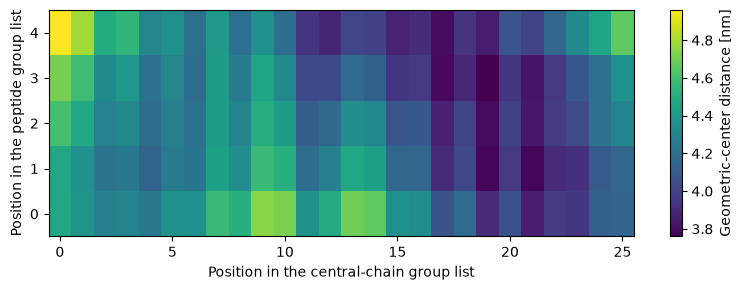

In [4]:
# Numeric selections on element='group' must contain group indices.
peptide_group_indices = np.unique(msm.get(
    molsys, element='atom', selection=peptide_atom_indices, group_index=True))
core_group_indices = np.unique(msm.get(
    molsys, element='atom', selection=core_atom_indices, group_index=True))
peptide_groups = msm.get(molsys, element='group', selection=peptide_group_indices,
                         atom_index=True)
core_groups = msm.get(molsys, element='group', selection=core_group_indices,
                      atom_index=True)
group_distances = msm.structure.get_distances(
    molsys, selection=peptide_groups, selection_2=core_groups,
    center_of_atoms=True, center_of_atoms_2=True, structure_indices=0, pbc=False)
plt.figure(figsize=(8, 3))
plt.imshow(puw.get_value(group_distances, to_unit='nm')[0], aspect='auto', origin='lower')
plt.xlabel('Position in the central-chain group list')
plt.ylabel('Position in the peptide group list')
plt.colorbar(label='Geometric-center distance [nm]')
plt.tight_layout()
plt.show()


(course-alzheimer-geometrical-measurements-angle)=
## 3. Measuring Orientation (Angles)

Define an opening angle using the first and last peptide CA atoms and a CA atom
near the middle of the central target chain. Select these atoms by their actual
names; arbitrary atom numbers need not identify CA atoms. The **middle atom in
the triplet is the vertex**, here on the target chain.

This one angle describes those three points. It is not a unique rigid-body
orientation or an aromatic-interaction criterion. All calculations here use
`pbc=False` on the supplied Cartesian coordinates, without fitting, alignment or
unwrapping. Angular results follow the active unit policy; conversion to degrees
below is an explicit presentation choice.


In [5]:
ca_atom_indices = np.asarray(msm.select(molsys, selection='atom_name=="CA"'))
peptide_ca_indices = np.intersect1d(peptide_atom_indices, ca_atom_indices)
core_ca_indices = np.intersect1d(core_atom_indices, ca_atom_indices)
atom_indices = [int(peptide_ca_indices[0]),
                int(core_ca_indices[len(core_ca_indices)//2]),
                int(peptide_ca_indices[-1])]
angle = msm.structure.get_angles(molsys, triplets=[atom_indices],
                                  structure_indices=0, pbc=False)
print('Source atom triplet:', atom_indices)
print('Angle with the middle atom as vertex:', puw.convert(angle, to_unit='degrees'))


Source atom triplet: [1857, 932, 1934]
Angle with the middle atom as vertex: [[18.226532935660543]] degree


:::{hint}
:class: dropdown

`msm.structure.get_angles()` accepts one triplet or an ordered list of triplets.
It returns shape `(n_structures, n_triplets)`. See
{func}`molsysmt.structure.get_angles` and {ref}`Tutorial_Get_angles`.
:::


(course-alzheimer-geometrical-measurements-challenge)=
## 🏆 Path A Challenge: The Geometric Analyst

1. Calculate the **distance matrix** between the geometric centers of all groups
   of the peptide and all groups of the first target chain. Retain the ordered
   group-index lists so you can interpret both matrix axes.
2. Find the peptide group closest to the target. State whether you mean a
   distance between geometric centers or the minimum distance over its atoms;
   these observables can select different groups.
3. Obtain an available backbone quartet for that group with
   `msm.chemical_states.get_dihedral_quartets()` and measure it with
   `msm.structure.get_dihedral_angles()`. A terminal group may lack the required
   neighboring atoms; do not invent a quartet when it is absent.

```{admonition} Key takeaway
:class: dropdown

Coordinates, populations, index correspondence and units make a geometric
observation interpretable. Geometry alone does not establish an interaction,
a plausible pose or binding affinity.
```

(course-alzheimer-geometrical-measurements-see-also)=
:::{seealso}
:class: dropdown

**API documentation**

- {func}`molsysmt.structure.get_distances` — Independent atom or center endpoints.
- {func}`molsysmt.structure.get_minimum_distances` — Minima with local endpoint positions.
- {func}`molsysmt.structure.get_angles` — Ordered triplets and a middle vertex.
- {func}`molsysmt.chemical_states.get_dihedral_quartets` — Available state-dependent quartets.
- {func}`molsysmt.structure.get_dihedral_angles` — Signed dihedral observations.

**Related modules and guides**

- Next: {ref}`Module 31: Proximity and Neighborhoods <course-alzheimer-proximity-neighborhoods>`.
- {ref}`Distances and neighborhoods <user-tools-distance-family>`.
- {ref}`Centering selected populations <Tutorial_Center>`.
:::
